# Week 7: finding objects and counting them (in-class exercises)

**Computational AI · Dr Mabrouka Abuhmida · University of South Wales**

In Week 6 we cleaned and prepared the coins image. Today we ask the question the coin counter exists to answer: how many coins are there? You will turn the image into a table of objects, and then use what you learned about outliers in Week 3 to check it.

1. Threshold the image and count the objects
2. Clean the mask step by step
3. Measure every object into a table
4. Consolidate: build one function and test it on a noisy image

Work in pairs. Write short answers wherever you see **Your answer**.

**Submission:** when you finish, run all cells (Kernel > Restart and Run All) and upload this notebook through the student submission app: https://student-app-production-10ec.up.railway.app/

## Dataset instructions

- The image is `skimage.data.coins`, the same one as Week 6. There is **no file to upload**.
- There are 24 coins. Count them by eye before you run any code, and write your number down.
- Libraries: `numpy`, `pandas`, `matplotlib`, `scipy`, `scikit-image` (0.21 or later).
- Newer scikit-image versions (0.26 and later) warn that `min_size` in `remove_small_objects` has been renamed `max_size`. The warning is harmless today, and the setup cell hides it.

## Setup and data loading

Run this cell as it is.

scikit-image version: 0.26.0
shape: (303, 384)  data type: uint8


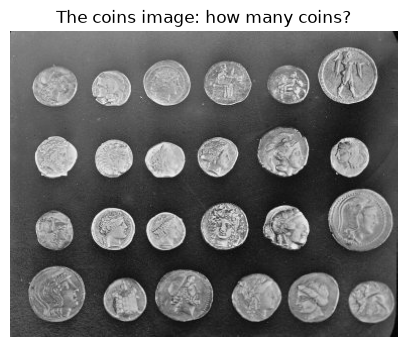

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
from scipy import ndimage as ndi
from skimage import data, util, filters, morphology, measure, segmentation

warnings.filterwarnings("ignore", category=FutureWarning)
print("scikit-image version:", skimage.__version__)

coins = data.coins()
print("shape:", coins.shape, " data type:", coins.dtype)

plt.figure(figsize=(5, 4))
plt.imshow(coins, cmap="gray")
plt.title("The coins image: how many coins?")
plt.axis("off")
plt.show()

## Worked example: opening on a tiny mask

A mask is an array of `True` and `False`: `True` where we think there is an object. **Opening** is an erosion followed by a dilation. Erosion shrinks every object, so tiny specks disappear. Dilation then grows what is left back to its size.

- `morphology.disk(r)` makes a round neighbourhood of radius `r`.
- `morphology.opening(mask, footprint)` returns the cleaned mask.
- **Risk:** a big footprint also removes thin parts of real objects.

This cell is complete.

In [2]:
tiny = np.zeros((9, 9), dtype=bool)
tiny[2:7, 2:7] = True        # a 5 by 5 object
tiny[0, 8] = True            # a one pixel speck

opened = morphology.opening(tiny, morphology.disk(1))
print("objects before:", measure.label(tiny, connectivity=1).max())
print("objects after opening:", measure.label(opened, connectivity=1).max())

objects before: 2
objects after opening: 1


### Student Task 1: threshold and count (slide exercise 1)

**Goal:** turn the image into a mask and count the objects in it.

**Steps:**
1. Use `filters.threshold_otsu(coins)` to find a threshold. Print it.
2. Make a mask with `coins > threshold`.
3. Count the objects with `measure.label(mask, connectivity=1).max()`.

**Expected output:** the threshold is 107 and the count is 154. That is far more than 24.

**Reflection question:** why is the count so high? Look at the mask before you answer.

In [ ]:
# TODO: Complete this task
# Hint: filters.threshold_otsu(image) returns one number
# Hint: measure.label numbers each connected object; .max() is the count
# Add your code here

**Your answer:**

_Write here._

## Visualisation 1: where Otsu puts the threshold

Otsu's method picks the threshold that best separates two groups of pixel values. The red line is its choice. The right panel shows the raw mask. Look at the top of the mask.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(coins.ravel(), bins=64, color="#CA0437")
axes[0].axvline(filters.threshold_otsu(coins), color="#333333", linestyle="--")
axes[0].set_title("Histogram, with Otsu's threshold")
axes[0].set_xlabel("pixel value")
axes[1].imshow(coins > filters.threshold_otsu(coins), cmap="gray")
axes[1].set_title("The raw mask")
axes[1].axis("off")
plt.tight_layout()
plt.show()

### Student Task 2: clean the mask, step by step (slide exercise 2)

**Goal:** see how each cleaning step changes the count.

**Steps:**
1. Open the mask with `morphology.opening(mask, morphology.disk(2))`. Count the objects.
2. Remove small objects with `morphology.remove_small_objects(opened, min_size=100)`. Count again.
3. Fill the holes with `ndi.binary_fill_holes(cleaned)`. Count again.
4. Print the four counts in one line.

**Expected output:** 154, then 31, then 28, then 25. There are still 25, not 24.

**Reflection question:** which step removed the most false objects, and which step fixed a real problem with the coins themselves?

In [ ]:
# TODO: Complete this task
# Hint: opened, then small removed, then holes filled
# Hint: count = measure.label(m, connectivity=1).max()
# Add your code here

**Your answer:**

_Write here._

## Visualisation 2: the mask at each step

Four panels, one per step. Watch the speckle disappear, and look again at the top edge.

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (title, m) in zip(axes, [("raw", mask), ("opened", opened), ("small removed", cleaned), ("holes filled", filled)]):
    ax.imshow(m, cmap="gray")
    ax.set_title(f"{title}: {count(m)}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Student Task 3: measure every object into a table (slide exercise 3)

**Goal:** turn the objects into rows of a table, as we did with the ward patients.

**Steps:**
1. Label the filled mask with `labels = measure.label(filled, connectivity=1)`.
2. Use `measure.regionprops(labels)` to get the properties of each object.
3. Build a DataFrame with one row per object and the columns `label`, `area`, `solidity` and `bbox`. (`p.label`, `p.area`, `p.solidity` and `p.bbox` are the properties.)
4. Sort by area, largest first, and print the top 5.

**Expected output:** 25 rows. The largest area is 6870, then 3038, 2534, 2205 and 1953. The median area is 1466.

**Reflection question:** what is unusual about the largest object? Look at its `bbox` and `solidity` (a value near 1 means a solid, compact shape).

In [ ]:
# TODO: Complete this task
# Hint: pd.DataFrame([{...} for p in measure.regionprops(labels)])
# Hint: df.sort_values("area", ascending=False)
# Add your code here

**Your answer:**

_Write here._

## Visualisation 3: look at what was flagged

Statistics find the unusual objects. Looking decides what they are. The flagged objects are outlined in red.

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5.4))
ax.imshow(coins, cmap="gray")
for _, row in df[df["flagged"]].iterrows():
    r0, c0, r1, c1 = row["bbox"]
    ax.add_patch(plt.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, edgecolor="#CA0437", linewidth=2))
    ax.text(c0, r0 - 4, f"area {row['area']}", color="#CA0437", fontsize=10)
ax.set_title("Flagged by the IQR rule")
ax.axis("off")
plt.show()

## Post-session task: the app, and your own photo

**Goal:** run the coin counter app, then try the idea on your own picture.

**Steps:**
1. Run the app from class: `streamlit run app.py`. Move the threshold slider and watch the count.
2. Try the border checkbox. Say what it removes.
3. Take a photo of coins (or any small round objects) on a plain surface. Load it with `io.imread`, convert it to greyscale with `color.rgb2gray`, and run `count_coins` on it (you will need `util.img_as_ubyte` first).
4. Write two sentences: what went wrong, and which Week 6 step would you try first?

In [ ]:
# TODO: Complete this task
# from skimage import io, color
# Add your code here

## Reflection

Weeks 2 to 6 said: understand, clean, transform. Today we added extract and check. In about 100 words, explain how the Week 3 outlier rule helped you find a problem that a person looking at the final count of 25 would not have seen, and what a statistic can never tell you by itself.

**Your answer:**

_Write here._

---

When you finish: Kernel > Restart and Run All, then upload the notebook through the student submission app: https://student-app-production-10ec.up.railway.app/

## References

- Gonzalez, R.C. and Woods, R.E. (2018) *Digital image processing*. 4th edn. New York: Pearson.
- Otsu, N. (1979) 'A threshold selection method from gray-level histograms', *IEEE Transactions on Systems, Man, and Cybernetics*, 9(1), pp. 62 to 66.
- scikit-image contributors (2024) *scikit-image documentation*. Available at: https://scikit-image.org/docs/stable/
- Tukey, J.W. (1977) *Exploratory data analysis*. Reading, MA: Addison-Wesley.
- van der Walt, S., Schönberger, J.L., Nunez-Iglesias, J., Boulogne, F., Warner, J.D., Yager, N., Gouillart, E. and Yu, T. (2014) 'scikit-image: image processing in Python', *PeerJ*, 2, e453.